# **Aplicación de RNN y LSTM a series de tiempo: radiación solar INMET (2019–2025)**

### **1. Contextualización y fuente de datos**

- **Fuente oficial:** [Instituto Nacional de Meteorología (INMET), Brasil](https://portal.inmet.gov.br/).
- **Repositorio:** [Kalbam/Datos](https://github.com/Kalbam/Datos/tree/main).
- **Estación meteorológica:** A710, Paranaíba, Mato Grosso do Sul, Brasil.
- **Periodo de estudio:** 2019–2025.
- **Resolución temporal:** horaria.
- **Variable de interés:** radiación solar global.

### **2. Fundamento conceptual: ¿qué es una serie de tiempo?**

Una **serie de tiempo** es una sucesión de observaciones registradas en instantes cronológicamente ordenados, que puede expresarse como:

$$
\mathcal{R}=\{R_t\}_{t=1}^{N}=(R_1,R_2,\ldots,R_N),
$$

donde $R_t$ representa la **radiación solar global registrada en la hora $t$** y $N$ corresponde al número total de observaciones.


### **4. Esquema metodológico**

```{figure} ./imgs/flujo_series_temporales.png
:name: flujo-series-temporales
:align: center
:alt: 

Flujo del ejemplo extraído: lectura, partición temporal, escalado, construcción de
ventanas, LSTM, predicción y evaluación.
```

## **1. Importaciones y configuración**
- **Unidad:** la columna INMET de radiación global se expresa en **kJ/m² por hora**. Se conserva esa unidad en todo el análisis; no confundir con W/m².
- **Requisitos:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `statsmodels`, `scikit-learn` y `tensorflow`.
- **Ejecución:** todas las celdas se ejecutan de arriba hacia abajo dentro de Jupyter.

In [1]:
# Ejecutar solo si faltan dependencias:
# %pip install numpy pandas matplotlib seaborn statsmodels scikit-learn tensorflow requests
import io, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
np.random.seed(SEED); random.seed(SEED)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .22})

## **2. ETL: descarga, lectura y calidad de datos**

- **ETL:** extraer (*Extract*) los siete CSV, transformar fechas y números (*Transform*) y construir la serie horaria (*Load*).
- **Rango:** **2019–2025 completos**. Se usan las **fechas reales**, sin reemplazarlas por una secuencia artificial.
- **Descarga:** `raw.githubusercontent.com` permite acceder directamente al CSV alojado en GitHub. Si Jupyter no tiene internet, descargar los siete archivos y ajustar `CARPETA_LOCAL`.

In [ ]:
BASE = 'https://raw.githubusercontent.com/Kalbam/Datos/main/'
CARPETA_LOCAL = None  # Alternativa: './datos_inmet' si los CSV se guardaron localmente
ARCHIVOS = [f'INMET_CO_MS_A710_PARANAIBA_01-01-{a}_A_31-12-{a}.CSV' for a in range(2019, 2025)]

def leer_inmet(nombre):
    if CARPETA_LOCAL:
        origen = f'{CARPETA_LOCAL}/{nombre}'
    else:
        url = BASE + nombre
        try:
            r = requests.get(url, timeout=35); r.raise_for_status(); origen = io.BytesIO(r.content)
        except requests.RequestException as exc:
            raise RuntimeError(f'No se descargó {url}. Revisa el nombre en GitHub o CARPETA_LOCAL.') from exc
    # Cabecera de metadatos INMET en primeras 8 líneas; CSV con ';' y coma decimal
    d = pd.read_csv(origen, sep=';', encoding='latin1', skiprows=8, dtype=str)
    d.columns = d.columns.str.strip().str.upper()
    fcol = next((c for c in d if c.startswith('DATA')), None)
    hcol = next((c for c in d if 'HORA' in c), None)
    rcol = next((c for c in d if 'RADIACAO' in c or 'RADIAÇÃO' in c), None)
    if not all([fcol,hcol,rcol]):
        raise ValueError(f'Columnas INMET inesperadas en {nombre}: {d.columns.tolist()}')
    fecha = d[fcol].astype(str).str.strip()
    hora = (d[hcol].astype(str).str.upper().str.replace('UTC','',regex=False)
            .str.replace(':','',regex=False).str.strip().str.zfill(4).str[:4])
    # INMET publica fechas YYYY/MM/DD o YYYY-MM-DD; distinguir formatos explícitamente
    ftexto = fecha.str.replace('/','-',regex=False)
    t = pd.to_datetime(ftexto + ' ' + hora, format='%Y-%m-%d %H%M', errors='coerce')
    if t.isna().mean() > .2:
        t = pd.to_datetime(ftexto + ' ' + hora, dayfirst=True, errors='coerce')
    valores = pd.to_numeric(d[rcol].astype(str).str.strip().str.replace(',','.',regex=False), errors='coerce')
    valores = valores.mask(valores < 0)  # Radiación negativa: dato inválido/faltante
    return pd.DataFrame({'datetime':t, 'RADIACAO_GLOBAL':valores, 'anio_archivo':int(nombre.split('_01-01-')[1][:4])})

df_raw = pd.concat([leer_inmet(a) for a in ARCHIVOS], ignore_index=True)
if df_raw.datetime.notna().sum() == 0: raise ValueError('No se pudo interpretar ninguna fecha; revisar estructura INMET.')
print('Archivos descargados:', len(ARCHIVOS), '| Filas originales:', len(df_raw))
print('Fechas ilegibles:', int(df_raw.datetime.isna().sum()))
display(df_raw.head(5))

Archivos descargados: 6 | Filas originales: 52608
Fechas ilegibles: 0


,datetime,RADIACAO_GLOBAL,anio_archivo
0,2019-01-01 00:00:00,NaN,2019
1,2019-01-01 01:00:00,NaN,2019
2,2019-01-01 02:00:00,NaN,2019
3,2019-01-01 03:00:00,NaN,2019
4,2019-01-01 04:00:00,NaN,2019


### **2.1. Regularidad temporal, faltantes y ceros observados**
- **NaN:** ausencia de medición; candidato a imputación. Valores negativos de radiación se consideran inválidos y pasan a `NaN`.
- **Cero registrado:** medición válida posible (especialmente de noche); **no se reemplaza automáticamente**.
- **Duplicados de fecha:** se consolidan por promedio de valores disponibles. Se agrega una rejilla horaria continua y se identifican horas sin registro.
- **Hora:** los archivos INMET utilizan **UTC**; se conserva la referencia temporal del registro.

In [3]:
df0 = (df_raw.dropna(subset=['datetime']).groupby('datetime')['RADIACAO_GLOBAL']
       .mean().sort_index().to_frame())
reloj = pd.date_range(df0.index.min(), df0.index.max(), freq='h', name='datetime')
df_INMET = df0.reindex(reloj)
col = 'RADIACAO_GLOBAL'
df_INMET['faltante_original'] = df_INMET[col].isna()
df_INMET['hour'] = df_INMET.index.hour
df_INMET['dayofyear'] = df_INMET.index.dayofyear
df_INMET['month'] = df_INMET.index.month
df_INMET['year'] = df_INMET.index.year

print('Periodo UTC:', df_INMET.index.min(), '→', df_INMET.index.max())
print('Horas:', len(df_INMET), '| Ausentes:', df_INMET.faltante_original.sum(),
      '| % faltante:', round(100*df_INMET.faltante_original.mean(),2),
      '| Ceros medidos:', int(df_INMET[col].eq(0).sum()))
display(df_INMET.groupby('year').agg(horas=(col,'size'), faltantes=('faltante_original','sum'),
                                     ceros=(col,lambda x: x.eq(0).sum())).rename_axis('Año'))

Periodo UTC: 2019-01-01 00:00:00 → 2024-12-31 23:00:00
Horas: 52608 | Ausentes: 28395 | % faltante: 53.97 | Ceros medidos: 5559


,horas,faltantes,ceros
Año,,,
2019,8760,4359,4
2020,8784,7896,1
2021,8760,8747,9
2022,8760,2832,2516
2023,8760,605,3012
2024,8784,3956,17


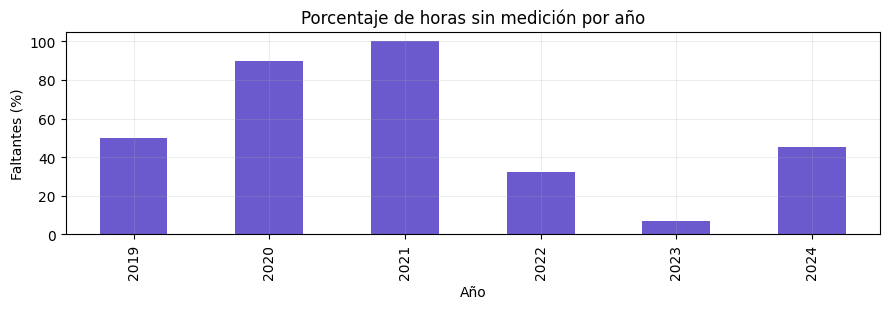

In [4]:
# Calidad anual: porcentaje faltante (sin inventar ceros)
calidad = 100 * df_INMET['faltante_original'].groupby(df_INMET.year).mean()
ax = calidad.plot.bar(color='slateblue', figsize=(9,3.2), title='Porcentaje de horas sin medición por año')
ax.set(xlabel='Año', ylabel='Faltantes (%)'); plt.tight_layout(); plt.show()

## **3. Imputación estacional**
El EDA original emplea **promedio por día del año y hora**. Conservamos esa idea, pero imputamos **solo `NaN`**, no radiación nocturna igual a cero:

$$
\boxed{\widehat R_t=\frac{1}{|G(d_t,h_t)|}\sum_{s\in G(d_t,h_t)}R_s},\qquad
G(d,h)=\{s:R_s\text{ observado},\ d_s=d,\ h_s=h\}.
$$

- **Fallback:** si el grupo `(día del año, hora)` no contiene datos observados, usar el promedio de la **hora del día**, y finalmente cero cuando no exista dato de esa hora.
- **EDA descriptivo:** se usan todos los años para explorar los datos (no para evaluar pronósticos).
- **Pronóstico:** posteriormente se recalculan estos promedios **solo en cada entrenamiento temporal**.

In [5]:
# Imputación estacional descriptiva: misma idea del EDA RAD, conservando ceros nocturnos
base = df_INMET[col]
media_dia_hora = base.groupby([df_INMET.dayofyear, df_INMET.hour]).mean()
media_hora = base.groupby(df_INMET.hour).mean()
claves = pd.MultiIndex.from_arrays([df_INMET.dayofyear, df_INMET.hour])
completado = pd.Series(media_dia_hora.reindex(claves).to_numpy(), index=df_INMET.index)
completado = completado.fillna(pd.Series(df_INMET.hour.map(media_hora), index=df_INMET.index)).fillna(0)
df_INMET['RADIACAO_GLOBAL_IMPUTADA'] = base.where(base.notna(), completado).clip(lower=0)
print('Valores imputados:', int(df_INMET.faltante_original.sum()),
      '| Faltantes restantes:', int(df_INMET.RADIACAO_GLOBAL_IMPUTADA.isna().sum()))
print('Ceros originales conservados:', bool((df_INMET.loc[base.eq(0),'RADIACAO_GLOBAL_IMPUTADA']==0).all()))

Valores imputados: 28395 | Faltantes restantes: 0
Ceros originales conservados: True


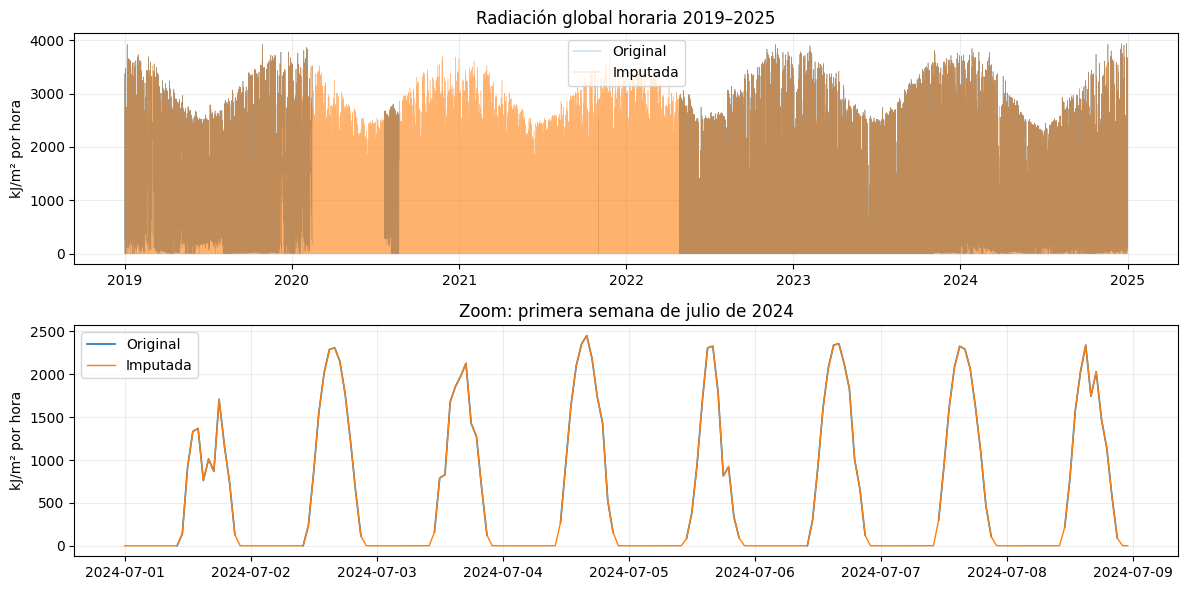

In [6]:
# Serie original e imputada; zoom en una semana reciente
zoom = df_INMET.loc['2024-07-01':'2024-07-08']
fig, ax = plt.subplots(2,1,figsize=(12,6),sharex=False)
ax[0].plot(df_INMET.index, df_INMET[col], lw=.35, alpha=.7, label='Original')
ax[0].plot(df_INMET.index, df_INMET.RADIACAO_GLOBAL_IMPUTADA, lw=.3, alpha=.6, label='Imputada')
ax[0].set(title='Radiación global horaria 2019–2025', ylabel='kJ/m² por hora'); ax[0].legend()
ax[1].plot(zoom.index, zoom[col],lw=1.2,label='Original'); ax[1].plot(zoom.index,zoom.RADIACAO_GLOBAL_IMPUTADA,lw=1,label='Imputada')
ax[1].set(title='Zoom: primera semana de julio de 2024',ylabel='kJ/m² por hora'); ax[1].legend()
plt.tight_layout();plt.show()

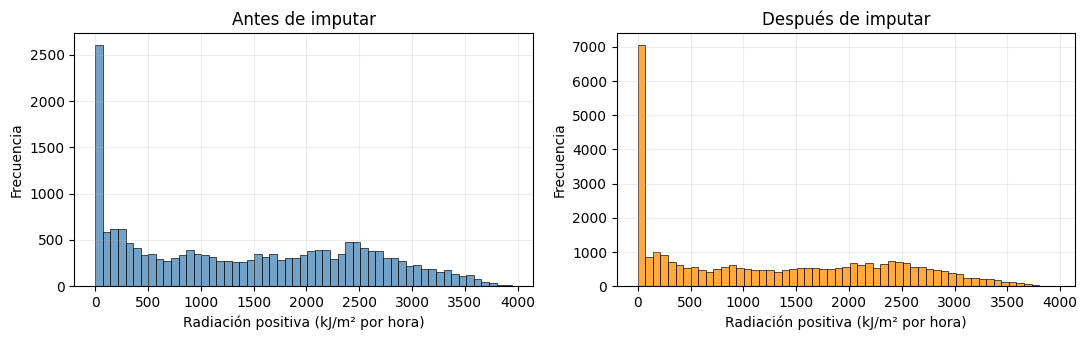

In [7]:
# Comparación de distribuciones: solo horas con radiación positiva
fig, ax = plt.subplots(1,2,figsize=(11,3.5))
sns.histplot(df_INMET.loc[df_INMET[col]>0,col],bins=55,ax=ax[0],color='steelblue')
sns.histplot(df_INMET.loc[df_INMET.RADIACAO_GLOBAL_IMPUTADA>0,'RADIACAO_GLOBAL_IMPUTADA'],
             bins=55,ax=ax[1],color='darkorange')
ax[0].set_title('Antes de imputar'); ax[1].set_title('Después de imputar')
for a in ax: a.set(xlabel='Radiación positiva (kJ/m² por hora)',ylabel='Frecuencia')
plt.tight_layout();plt.show()

## **4. EDA HORARIO**
**Objetivo:** estudiar tendencia visible, variabilidad, ciclo diario, distribución y dependencia temporal de la radiación registrada hora a hora. Los valores **0** se conservan para representar correctamente las noches.

In [8]:
# Estadísticos horarios: N, media, desviación, cuartiles, extremos, asimetría
serie_h = df_INMET['RADIACAO_GLOBAL_IMPUTADA']
def tabla_estadistica(s):
    return pd.DataFrame({'N':[s.count()],'Media':[s.mean()],'DE':[s.std()],
      'Mín':[s.min()],'Q1':[s.quantile(.25)],'Mediana':[s.median()],
      'Q3':[s.quantile(.75)],'Máx':[s.max()],'Asimetría':[s.skew()]})
display(tabla_estadistica(serie_h).round(3))

,N,Media,DE,Mín,Q1,Mediana,Q3,Máx,Asimetría
0,52608,784.616,1052.95,0.0,0.0,27.238,1595.0,3943.9,1.027


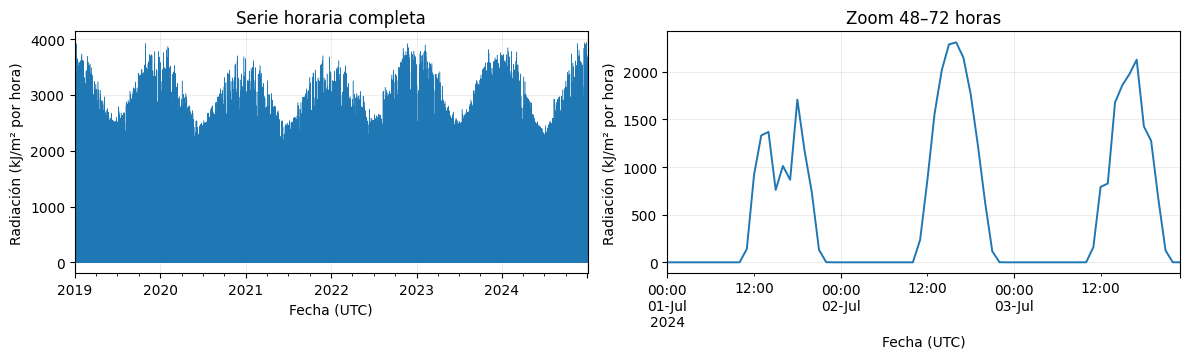

In [9]:
# Serie horaria y zoom de 48 h
fig, ax=plt.subplots(1,2,figsize=(12,3.7))
serie_h.plot(ax=ax[0],lw=.35);serie_h.loc['2024-07-01':'2024-07-03'].plot(ax=ax[1],lw=1.4)
ax[0].set_title('Serie horaria completa');ax[1].set_title('Zoom 48–72 horas')
for a in ax:a.set(xlabel='Fecha (UTC)',ylabel='Radiación (kJ/m² por hora)')
plt.tight_layout();plt.show()

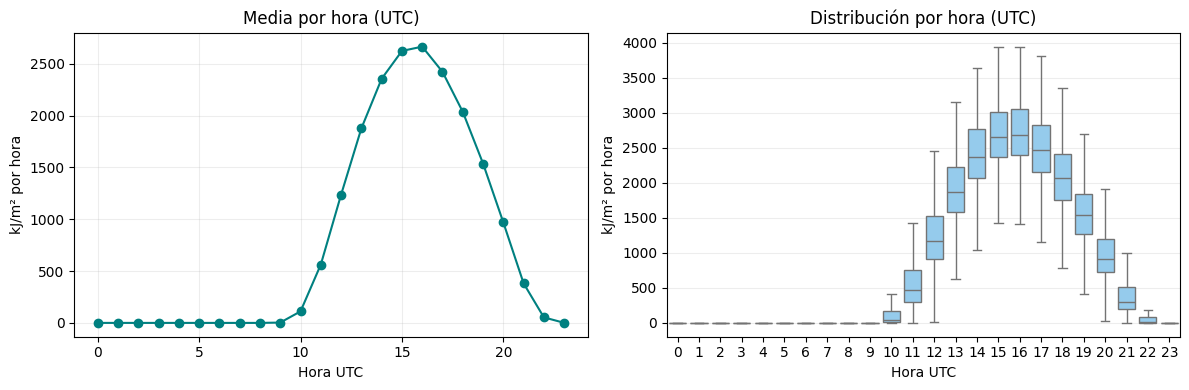

In [10]:
# Distribución horaria: promedios y diagrama de caja
horario = df_INMET.groupby('hour')['RADIACAO_GLOBAL_IMPUTADA']
fig,ax=plt.subplots(1,2,figsize=(12,4))
horario.mean().plot(marker='o',ax=ax[0],color='teal')
sns.boxplot(x=df_INMET.hour, y=serie_h,ax=ax[1],color='lightskyblue',showfliers=False)
ax[0].set(title='Media por hora (UTC)',xlabel='Hora UTC',ylabel='kJ/m² por hora')
ax[1].set(title='Distribución por hora (UTC)',xlabel='Hora UTC',ylabel='kJ/m² por hora')
plt.tight_layout();plt.show()

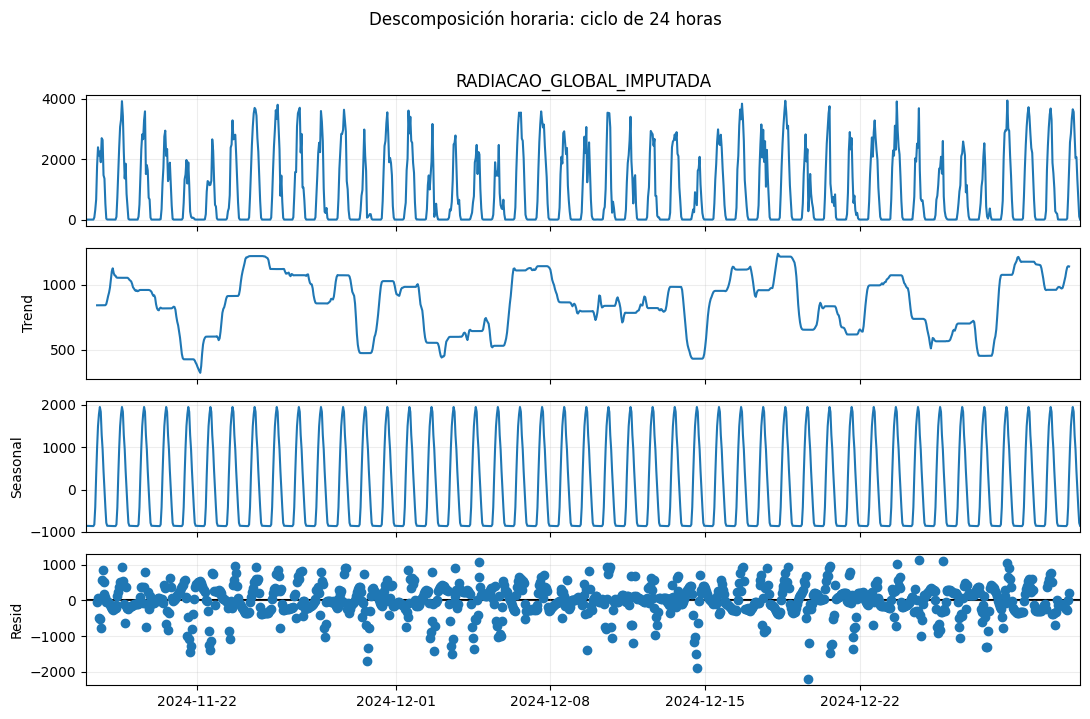

In [11]:
# Descomposición aditiva del ciclo horario (24 horas) en el tramo final
s24=serie_h.tail(24*45)
des=seasonal_decompose(s24,model='additive',period=24)
fig=des.plot();fig.set_size_inches(11,7);fig.suptitle('Descomposición horaria: ciclo de 24 horas',y=1.02)
plt.tight_layout();plt.show()

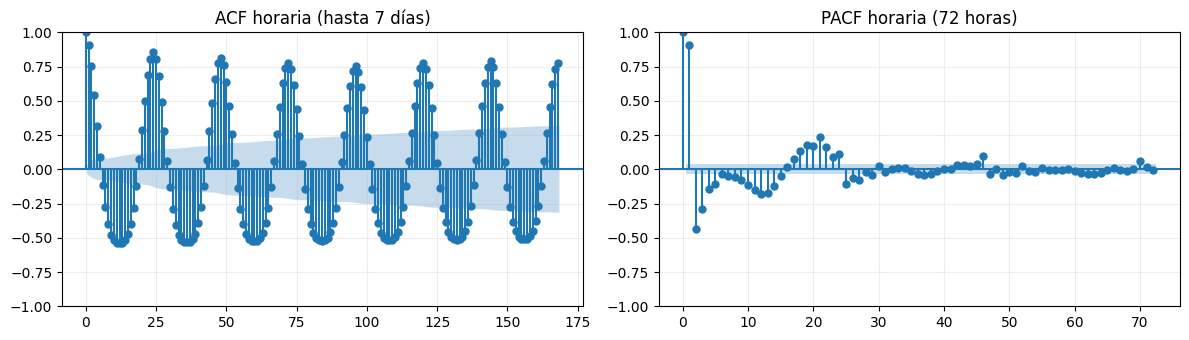

In [12]:
# ACF y PACF horarias: 7 días de rezagos con muestra reciente para rapidez
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
s=serie_h.tail(24*120)
plot_acf(s,lags=24*7,ax=ax[0]);plot_pacf(s,lags=72,method='ywm',ax=ax[1])
ax[0].set_title('ACF horaria (hasta 7 días)');ax[1].set_title('PACF horaria (72 horas)')
plt.tight_layout();plt.show()

## **5. EDA DIARIO**
**Agregación:** $\overline R_d=\frac{1}{n_d}\sum_{t\in d}R_t$. La **media diaria** conserva la unidad de la observación horaria (**kJ/m² por hora**, promediada sobre las horas). Si se necesita energía diaria, debe utilizarse la **suma** en kJ/m² por día.

,N,Media,DE,Mín,Q1,Mediana,Q3,Máx,Asimetría
0,2192,784.616,180.088,87.646,680.697,775.804,897.07,1254.023,-0.259


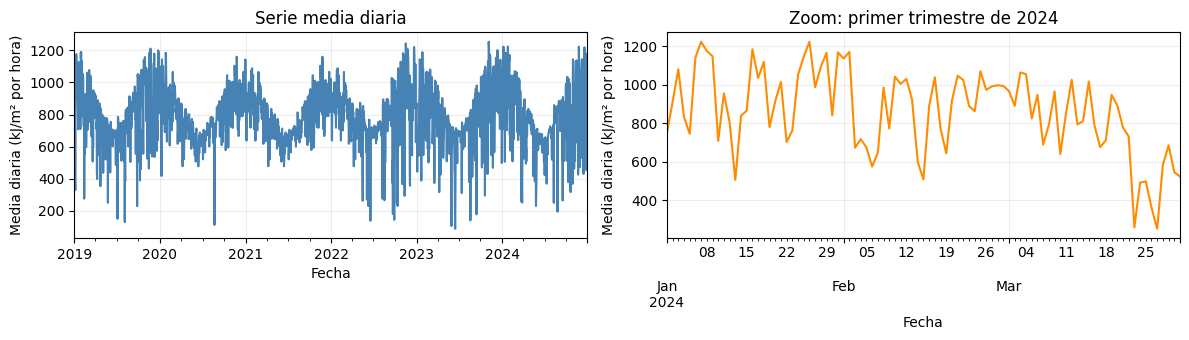

In [13]:
# Serie y estadísticos diarios
serie_d=serie_h.resample('D').mean()
energia_d=serie_h.resample('D').sum()  # Energía acumulada diaria: kJ/m²/día
display(tabla_estadistica(serie_d).round(3))
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
serie_d.plot(ax=ax[0],color='steelblue');serie_d.loc['2024-01':'2024-03'].plot(ax=ax[1],color='darkorange')
ax[0].set_title('Serie media diaria');ax[1].set_title('Zoom: primer trimestre de 2024')
for a in ax:a.set(xlabel='Fecha',ylabel='Media diaria (kJ/m² por hora)')
plt.tight_layout();plt.show()

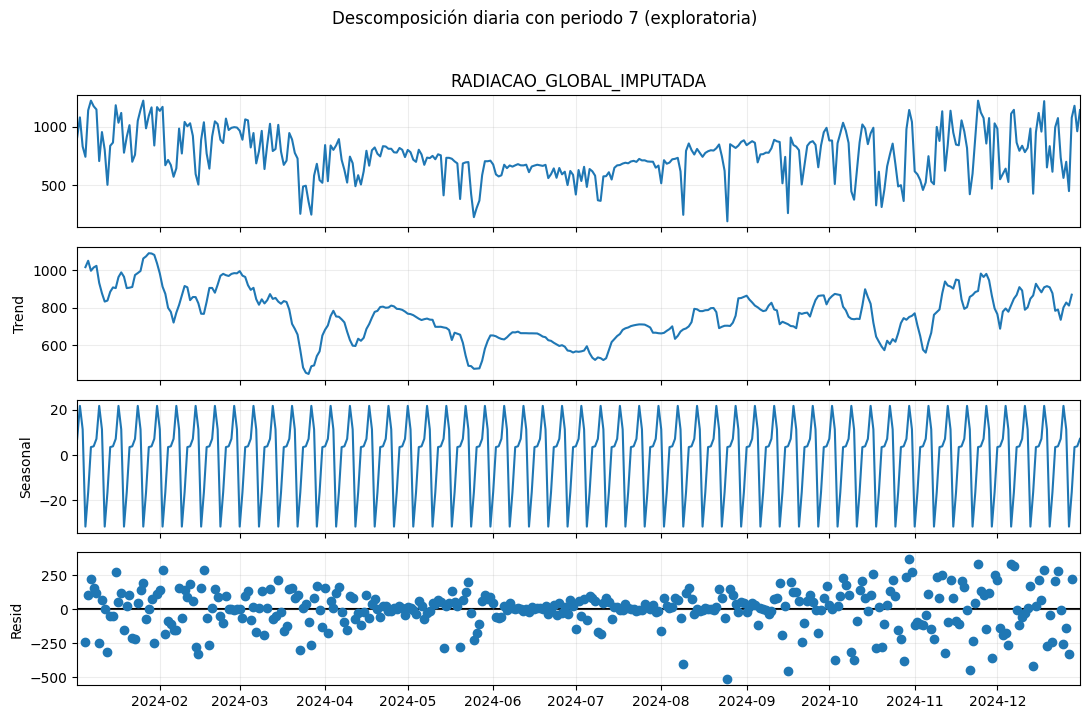

In [14]:
# Descomposición semanal ilustrativa (NO asumir que existe estacionalidad semanal física)
sem=seasonal_decompose(serie_d.tail(365),model='additive',period=7)
fig=sem.plot();fig.set_size_inches(11,7);fig.suptitle('Descomposición diaria con periodo 7 (exploratoria)',y=1.02)
plt.tight_layout();plt.show()

,count,mean,std,min,25%,50%,75%,max
Dia,,,,,,,,
Monday,313.0,787.64,175.92,261.91,681.84,779.12,898.28,1226.12
Tuesday,314.0,787.12,181.82,104.71,671.78,783.70,908.28,1184.44
Wednesday,313.0,786.03,179.20,143.53,676.37,774.27,883.38,1243.29
Thursday,313.0,782.47,182.34,87.65,685.00,772.29,894.74,1221.40
Friday,313.0,776.21,184.18,111.83,678.74,770.30,891.60,1223.88
Saturday,313.0,784.95,178.51,137.67,687.37,775.20,907.34,1183.49
Sunday,313.0,787.90,179.96,129.01,686.40,778.74,900.36,1254.02


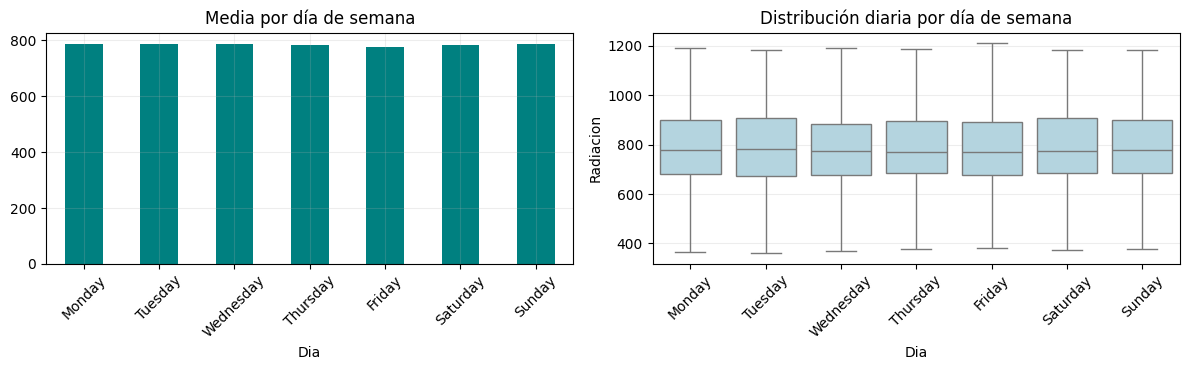

In [15]:
# EDA por día de la semana: media, boxplot y tabla
orden=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
tdia=serie_d.to_frame('Radiacion');tdia['Dia']=tdia.index.day_name()
display(tdia.groupby('Dia')['Radiacion'].describe().reindex(orden).round(2))
fig,ax=plt.subplots(1,2,figsize=(12,3.8))
tdia.groupby('Dia').Radiacion.mean().reindex(orden).plot.bar(ax=ax[0],color='teal')
sns.boxplot(data=tdia,x='Dia',y='Radiacion',order=orden,ax=ax[1],color='lightblue',showfliers=False)
for a in ax:a.tick_params(axis='x',rotation=45)
ax[0].set_title('Media por día de semana');ax[1].set_title('Distribución diaria por día de semana')
plt.tight_layout();plt.show()

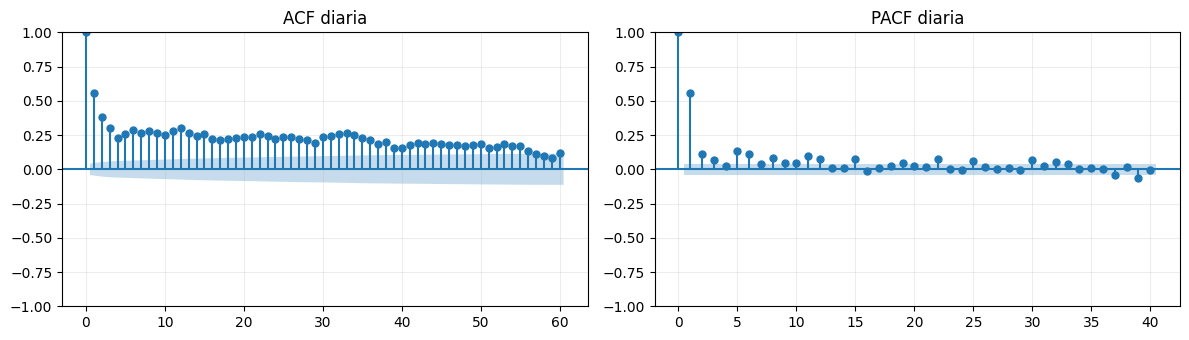

In [16]:
# ACF y PACF de la serie diaria
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
plot_acf(serie_d.dropna(),lags=60,ax=ax[0]);plot_pacf(serie_d.dropna(),lags=40,method='ywm',ax=ax[1])
ax[0].set_title('ACF diaria');ax[1].set_title('PACF diaria');plt.tight_layout();plt.show()

## **6. EDA MENSUAL**
**Agregación:** $\overline R_m=\operatorname{mean}\{R_t:t\in m\}$. Estudia cambios entre meses y estacionalidad anual. La **descomposición con periodo 12** corresponde a la frecuencia mensual; la etiqueta de unidad sigue siendo **kJ/m² por hora (media)**.

,N,Media,DE,Mín,Q1,Mediana,Q3,Máx,Asimetría
0,72,784.848,100.184,589.196,709.288,805.195,856.989,996.144,0.012


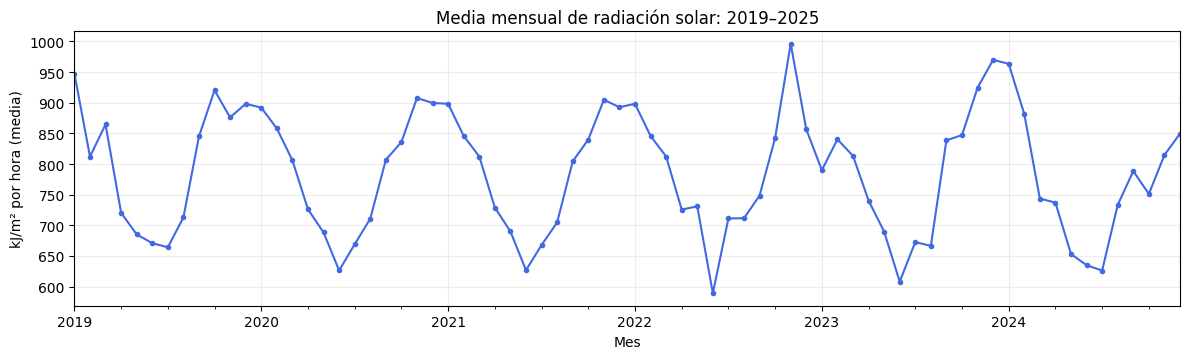

In [17]:
# Estadísticos y serie mensual
serie_m=serie_h.resample('MS').mean()
display(tabla_estadistica(serie_m).round(3))
fig,ax=plt.subplots(figsize=(12,3.7));serie_m.plot(ax=ax,marker='.',color='royalblue')
ax.set(title='Media mensual de radiación solar: 2019–2025',xlabel='Mes',ylabel='kJ/m² por hora (media)')
plt.tight_layout();plt.show()

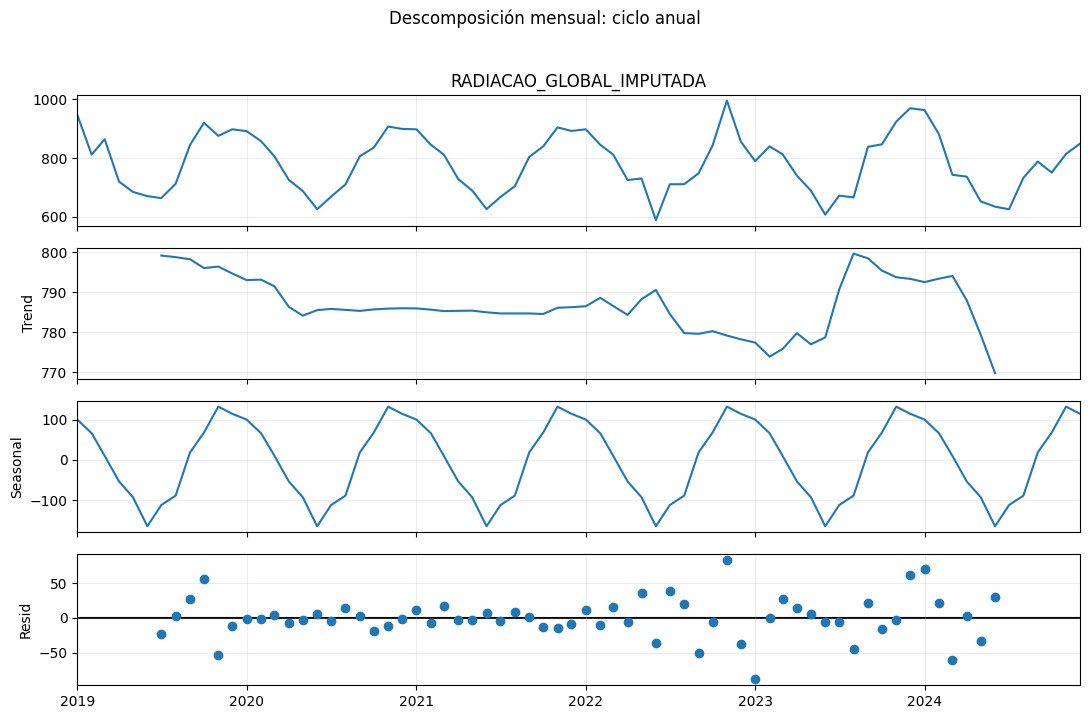

In [18]:
# Descomposición anual de la serie mensual, periodo=12
mens_des=seasonal_decompose(serie_m.dropna(),model='additive',period=12)
fig=mens_des.plot();fig.set_size_inches(11,7);fig.suptitle('Descomposición mensual: ciclo anual',y=1.02)
plt.tight_layout();plt.show()

,count,mean,std,min,25%,50%,75%,max
Mes,,,,,,,,
Ene,6.0,898.26,60.74,790.00,893.56,898.26,935.22,963.51
Feb,6.0,847.26,22.75,812.07,841.65,845.79,854.96,881.61
Mar,6.0,808.68,38.52,743.56,807.61,812.25,813.10,864.59
Abr,6.0,729.82,7.57,720.39,725.80,727.62,735.12,740.46
May,6.0,689.59,24.75,653.12,686.05,689.07,689.97,730.98
Jun,6.0,626.07,27.48,589.20,612.66,626.59,632.99,670.92
Jul,6.0,668.54,27.03,626.23,665.10,668.48,671.73,711.27
Ago,6.0,706.63,21.90,666.58,706.24,711.19,712.51,733.28
Sep,6.0,805.33,35.26,748.48,792.47,805.56,830.74,845.12


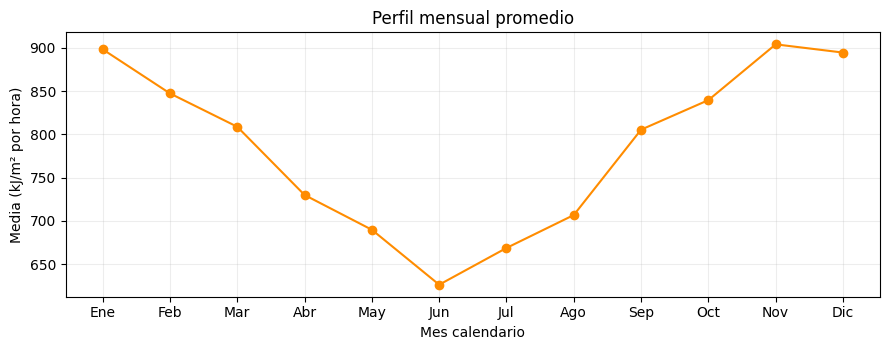

In [19]:
# Estadísticas por mes calendario y media climatológica
mnames=['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
tm=serie_m.to_frame('Radiacion');tm['Mes']=tm.index.month
display(tm.groupby('Mes')['Radiacion'].describe().rename(index=dict(enumerate(mnames,1))).round(2))
fig,ax=plt.subplots(figsize=(9,3.6))
tm.groupby('Mes').Radiacion.mean().plot(marker='o',ax=ax,color='darkorange')
ax.set(xticks=range(1,13),xticklabels=mnames,xlabel='Mes calendario',ylabel='Media (kJ/m² por hora)',title='Perfil mensual promedio')
plt.tight_layout();plt.show()

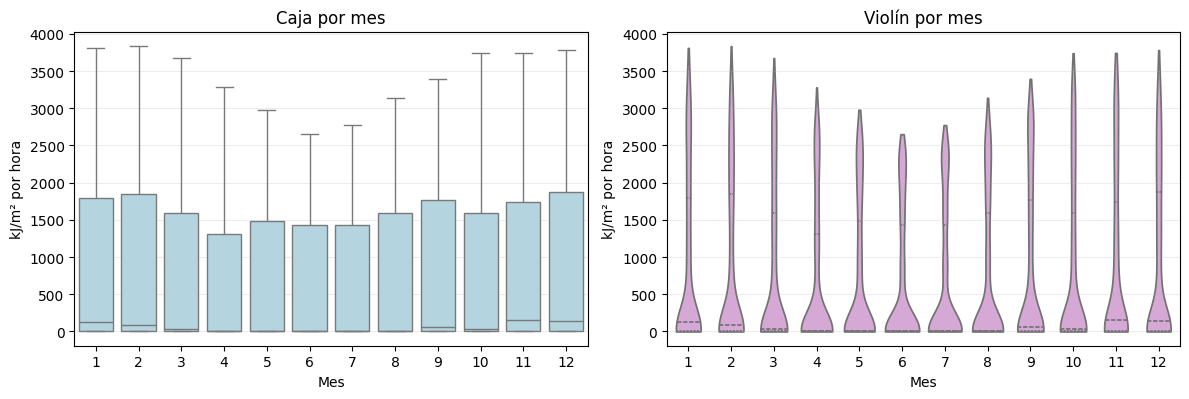

In [20]:
# Boxplot y violín por mes: muestreo reproducible para gráficos ligeros
muestra = df_INMET[['RADIACAO_GLOBAL_IMPUTADA','month']].sample(n=min(12000,len(df_INMET)),random_state=SEED)
fig,ax=plt.subplots(1,2,figsize=(12,4.1))
sns.boxplot(data=muestra,x='month',y='RADIACAO_GLOBAL_IMPUTADA',ax=ax[0],color='lightblue',showfliers=False)
sns.violinplot(data=muestra,x='month',y='RADIACAO_GLOBAL_IMPUTADA',ax=ax[1],color='plum',inner='quartile',cut=0)
for a in ax:a.set(xlabel='Mes',ylabel='kJ/m² por hora')
ax[0].set_title('Caja por mes');ax[1].set_title('Violín por mes')
plt.tight_layout();plt.show()

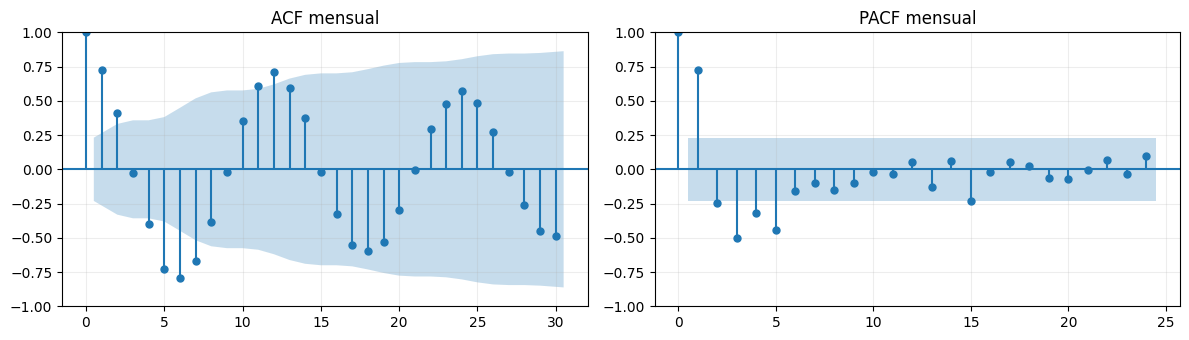

In [21]:
# Dependencia de la serie mensual
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
plot_acf(serie_m.dropna(),lags=min(30,len(serie_m)//2-1),ax=ax[0])
plot_pacf(serie_m.dropna(),lags=min(24,len(serie_m)//2-2),method='ywm',ax=ax[1])
ax[0].set_title('ACF mensual');ax[1].set_title('PACF mensual');plt.tight_layout();plt.show()

## **7. De la serie de tiempo a las redes RNN y LSTM**

**Problema:** predecir la radiación de la **hora siguiente** usando las $L$ observaciones previas.

$$
\boxed{\mathbf x_t=(R_{t-L},\ldots,R_{t-1})\in\mathbb R^{L\times1},\quad y_t=R_t},
\qquad \widehat R_t=f_\theta(\mathbf x_t).
$$

- **RNN simple:** actualiza un estado oculto $\mathbf h_t=\tanh(W_x\mathbf x_t+W_h\mathbf h_{t-1}+b)$.
- **LSTM:** utiliza compuertas y una celda de memoria para controlar qué información conservar.
- **Arquitecturas comparables:** `SimpleRNN` y `LSTM` con **1 o 2 capas**, distintas neuronas, `Dense(1)` lineal y **misma ventana temporal**.
- **Enfoque didáctico rápido:** seleccionar los **últimos 120 días** y un máximo de observaciones por partición. **El EDA anterior sí utilizó 2019–2025 completos**.

### **7.1. Segmento de modelado y conjunto final de prueba**
- **Prueba final:** último **20 %** cronológico del tramo de modelado, reservado antes de optimizar hiperparámetros.
- **Validación cruzada temporal:** dentro del 80 % inicial se generan particiones expansivas con `TimeSeriesSplit`, sin mezclar el futuro con el pasado.
- **Ceros nocturnos:** permanecen en el objetivo y en las entradas.
- **Alcance de imputación:** los valores de prueba faltantes se completan con reglas del entrenamiento; las métricas incluyen esos valores imputados como referencias cuando faltan mediciones reales. Para publicación científica se requeriría evaluar separadamente observaciones efectivamente medidas.


In [22]:
# Tamaño pequeño para Jupyter: 120 días horarios ≈ 2880 observaciones
DIAS_MODELO = 120  # Aumentar a 180/365 si hay capacidad de cómputo
WINDOW = 24       # L=24 observaciones horarias para predecir la siguiente
HORIZON = 1       # h=1 hora
HOURS = min(len(df_INMET), DIAS_MODELO*24)
serie_modelo = df_INMET[col].iloc[-HOURS:].copy()  # Sin imputar: se hace después, por split
n_test = int(np.ceil(len(serie_modelo)*.20))
serie_desarrollo=serie_modelo.iloc[:-n_test]
serie_test=serie_modelo.iloc[-n_test:]
print('Desarrollo:',len(serie_desarrollo),'horas | Prueba:',len(serie_test),'horas')
print('Fechas desarrollo:',serie_desarrollo.index.min(),'→',serie_desarrollo.index.max())
print('Fechas prueba:',serie_test.index.min(),'→',serie_test.index.max())

Desarrollo: 2304 horas | Prueba: 576 horas
Fechas desarrollo: 2024-09-03 00:00:00 → 2024-12-07 23:00:00
Fechas prueba: 2024-12-08 00:00:00 → 2024-12-31 23:00:00


### **7.2. Imputación y escalado sin información futura**
**Imputación estacional por hora y día del año:** en cada partición, la tabla de promedios se calcula **solamente con la parte de entrenamiento**. Si el periodo es corto y algún grupo carece de observaciones, utilizamos como respaldo la media de la hora y finalmente el cero.

**Escalado:** para un entrenamiento $T$, $z_t=(R_t-\min_T R)/(\max_T R-\min_T R)$; el escalador se ajusta **solo en $T$**. La LSTM y la RNN reciben entradas con forma $(\text{muestras},L,1)$.

In [23]:
def completar_desde_entrenamiento(train, otras):
    """Imputa NaN con promedios estacionales ajustados EXCLUSIVAMENTE en train."""
    g=pd.DataFrame({'v':train,'dia':train.index.dayofyear,'hora':train.index.hour})
    gh=g.groupby(['dia','hora']).v.mean(); hh=g.groupby('hora').v.mean()
    def completar(s):
        keys=pd.MultiIndex.from_arrays([s.index.dayofyear,s.index.hour])
        v=pd.Series(gh.reindex(keys).to_numpy(),index=s.index)
        v=v.fillna(pd.Series(s.index.hour.map(hh),index=s.index)).fillna(0)
        return s.where(s.notna(),v).clip(lower=0)
    return (completar(train),*[completar(s) for s in otras])

def crear_ventanas(valores, ventana=WINDOW):
    """Entradas históricas de L valores y siguiente valor como objetivo."""
    a=np.asarray(valores,dtype='float32').reshape(-1)
    X=np.stack([a[i-ventana:i] for i in range(ventana,len(a))])
    y=a[ventana:]
    return X[:,:,None], y

def preparar_split(train, val, window=WINDOW):
    """Transforma train/val con parámetros de train; val incluye contexto final de train."""
    tr,va=completar_desde_entrenamiento(train,[val]);sc=MinMaxScaler().fit(tr.to_numpy().reshape(-1,1))
    a=sc.transform(tr.to_numpy().reshape(-1,1)).ravel()
    b=sc.transform(pd.concat([tr.iloc[-window:],va]).to_numpy().reshape(-1,1)).ravel()
    Xtr,ytr=crear_ventanas(a,window);Xva,yva=crear_ventanas(b,window)
    return Xtr,ytr,Xva,yva,sc

### **7.3. Modelos, neuronas, capas y parada temprana**

La **validación cruzada temporal** prueba configuraciones pequeñas para escoger la arquitectura mediante el **MAE medio en validación**, sin utilizar el conjunto de prueba final. En cada pliegue:

- **Neurona recurrente:** unidad de memoria/estado oculto; más unidades aumentan la capacidad y los parámetros.
- **Capas:** una o dos capas recurrentes apiladas; con dos, la primera devuelve secuencias completas (`return_sequences=True`).
- **`EarlyStopping`:** detiene cuando la pérdida de validación deja de mejorar y restaura los mejores pesos.
- **Criterio:** comparar el error **desnormalizado** en kJ/m² por hora para que los pliegues sean comparables.

**Fórmulas:** $\mathrm{MAE}=\frac1n\sum_t|R_t-\widehat R_t|$ y $\mathrm{RMSE}=\sqrt{\frac1n\sum_t(R_t-\widehat R_t)^2}$.

**Configuraciones propuestas:** RNN y LSTM × {1 capa de 8 neuronas, 1 capa de 16 neuronas, 2 capas de 16 y 8 neuronas}. Dos pliegues; **máximo 12 épocas** por entrenamiento, con parada temprana para acelerar.

In [24]:
# TensorFlow se carga solamente al comenzar la aplicación neuronal
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
tf.keras.utils.set_random_seed(SEED)
CONFIGS=[('RNN',1,8),('RNN',1,16),('RNN',2,16),
         ('LSTM',1,8),('LSTM',1,16),('LSTM',2,16)]
EPOCHS_CV=12; BATCH=64; PATIENCE_CV=3

def crear_red(tipo,capas,unidades,ventana=WINDOW):
    """RNN o LSTM comparable; 2 capas usan segunda capa con mitad de unidades."""
    Capa = SimpleRNN if tipo=='RNN' else LSTM
    red=Sequential([Input(shape=(ventana,1))])
    red.add(Capa(unidades,return_sequences=capas==2))
    if capas==2: red.add(Capa(max(4,unidades//2)))
    red.add(Dropout(.10));red.add(Dense(1,activation='linear'))
    red.compile(optimizer='adam',loss='mae',metrics=['mse'])
    return red

print('Configuraciones:',CONFIGS)
crear_red('LSTM',2,16).summary()

I0000 00:00:1795138231.479038  282164 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795138231.728716  282164 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795138234.411912  282164 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Configuraciones: [('RNN', 1, 8), ('RNN', 1, 16), ('RNN', 2, 16), ('LSTM', 1, 8), ('LSTM', 1, 16), ('LSTM', 2, 16)]


W0000 00:00:1795138236.607784  282164 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 16)         │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 8)              │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,961 (7.66 KB)

 Trainable params: 1,961 (7.66 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Validación cronológica (expansiva), con muestra acotada y EarlyStopping
cv=TimeSeriesSplit(n_splits=2)
resultados=[]
for k,(ti,vi) in enumerate(cv.split(serie_desarrollo),1):
    train,valid=serie_desarrollo.iloc[ti],serie_desarrollo.iloc[vi]
    Xtr,ytr,Xva,yva,sc=preparar_split(train,valid)
    for tipo,capas,unidades in CONFIGS:
        tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(SEED)
        red=crear_red(tipo,capas,unidades)
        stop=EarlyStopping(monitor='val_loss',patience=PATIENCE_CV,mode='min',restore_best_weights=True)
        hist=red.fit(Xtr,ytr,validation_data=(Xva,yva),epochs=EPOCHS_CV,
                     batch_size=BATCH,callbacks=[stop],verbose=0,shuffle=False)
        yh=sc.inverse_transform(red.predict(Xva,verbose=0)).ravel()
        yr=sc.inverse_transform(yva.reshape(-1,1)).ravel()
        mae=mean_absolute_error(yr,yh)
        resultados.append({'Fold':k,'Modelo':tipo,'Capas':capas,'Neuronas':unidades,
                           'MAE':mae,'Épocas':len(hist.history['loss'])})
        print(f'Fold {k} | {tipo:4s} | capas={capas} | neuronas={unidades:2d} | MAE={mae:.2f} | épocas={len(hist.history["loss"])}')
res_cv=pd.DataFrame(resultados)
display(res_cv.round(3))

Fold 1 | RNN  | capas=1 | neuronas= 8 | MAE=299.58 | épocas=12
Fold 1 | RNN  | capas=1 | neuronas=16 | MAE=301.70 | épocas=12
Fold 1 | RNN  | capas=2 | neuronas=16 | MAE=283.49 | épocas=12
Fold 1 | LSTM | capas=1 | neuronas= 8 | MAE=439.97 | épocas=12
Fold 1 | LSTM | capas=1 | neuronas=16 | MAE=427.48 | épocas=12
Fold 1 | LSTM | capas=2 | neuronas=16 | MAE=402.41 | épocas=12
Fold 2 | RNN  | capas=1 | neuronas= 8 | MAE=318.88 | épocas=12
Fold 2 | RNN  | capas=1 | neuronas=16 | MAE=287.82 | épocas=12
Fold 2 | RNN  | capas=2 | neuronas=16 | MAE=282.94 | épocas=12
Fold 2 | LSTM | capas=1 | neuronas= 8 | MAE=384.51 | épocas=12
Fold 2 | LSTM | capas=1 | neuronas=16 | MAE=289.22 | épocas=12
Fold 2 | LSTM | capas=2 | neuronas=16 | MAE=343.60 | épocas=12


,Fold,Modelo,Capas,Neuronas,MAE,Épocas
0,1,RNN,1,8,299.581,12
1,1,RNN,1,16,301.696,12
2,1,RNN,2,16,283.491,12
3,1,LSTM,1,8,439.969,12
4,1,LSTM,1,16,427.484,12
5,1,LSTM,2,16,402.406,12
6,2,RNN,1,8,318.883,12
7,2,RNN,1,16,287.821,12
8,2,RNN,2,16,282.941,12
9,2,LSTM,1,8,384.508,12


,Modelo,Capas,Neuronas,MAE_medio,MAE_DE,Epocas_medias
0,RNN,2,16,283.216,0.389,12.0
1,RNN,1,16,294.759,9.811,12.0
2,RNN,1,8,309.232,13.649,12.0
3,LSTM,1,16,358.353,97.766,12.0
4,LSTM,2,16,373.002,41.584,12.0
5,LSTM,1,8,412.238,39.217,12.0


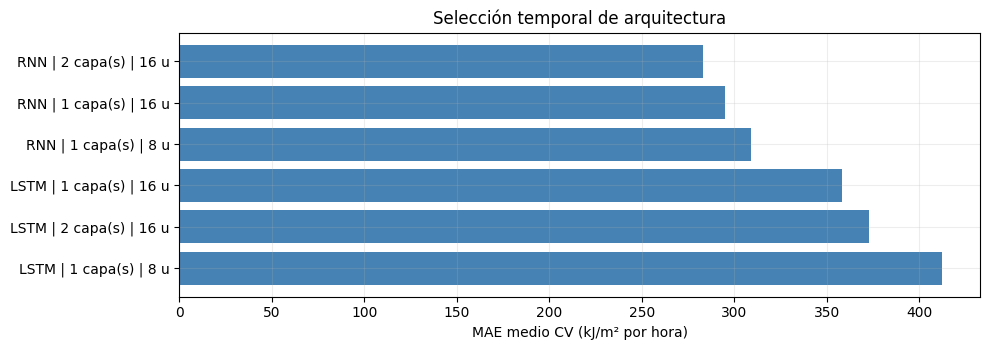

In [27]:
# Resumen estadístico y selección de arquitectura sin utilizar el conjunto test
resumen_cv = (res_cv.groupby(['Modelo', 'Capas', 'Neuronas'], as_index=False)
              .agg(MAE_medio=('MAE', 'mean'), MAE_DE=('MAE', 'std'),
                   Epocas_medias=('Épocas', 'mean')))

resumen_cv = resumen_cv.sort_values('MAE_medio').reset_index(drop=True)
display(resumen_cv.round(3))  # Ordena los modelos del menor al mayor error

# Gráfico comparativo de arquitecturas
fig, ax = plt.subplots(figsize=(10, 3.6))
labels = [f'{r.Modelo} | {r.Capas} capa(s) | {r.Neuronas} u'
          for r in resumen_cv.itertuples(index=False)]  # Nombres de las arquitecturas

ax.barh(labels[::-1], resumen_cv.MAE_medio.to_numpy()[::-1], color='steelblue')
ax.set(xlabel='MAE medio CV (kJ/m² por hora)',
       title='Selección temporal de arquitectura')
plt.tight_layout()
plt.show()


### **7.4. Evaluación final: entrenamiento, validación y prueba**

- Para cada familia, el tramo de desarrollo se divide cronológicamente en **85 % entrenamiento** y **15 % validación interna** para `EarlyStopping`.
- Se evalúa **una sola vez** sobre el conjunto final de prueba (20 %), reutilizando únicamente parámetros aprendidos sobre el pasado.
- **Línea base:** pronóstico ingenuo estacional de 24 h, para comprobar si las redes superan un método simple.
- **Métricas:** MAE, RMSE, $R^2$ y sesgo $\overline{\widehat R-R}$; acompañamos con curvas de pérdida y valores predichos frente a observados.

In [29]:
# 1. Seleccionar la mejor arquitectura de cada familia según el MAE de validación
mejores = resumen_cv.sort_values('MAE_medio').drop_duplicates('Modelo')
display(mejores[['Modelo', 'Capas', 'Neuronas', 'MAE_medio']].round(3))

# 2. Separar entrenamiento y validación final, manteniendo el orden cronológico
n_val = max(WINDOW + 10, int(.15 * len(serie_desarrollo)))
tr_final = serie_desarrollo.iloc[:-n_val]  # Primer 85 % aproximadamente
va_final = serie_desarrollo.iloc[-n_val:]  # Último 15 % aproximadamente
Xtr, ytr, Xva, yva, sc = preparar_split(tr_final, va_final)  # Imputación, escalado y ventanas

# 3. Preparar el test con contexto histórico, sin ajustar parámetros con el test
_, test_imp = completar_desde_entrenamiento(tr_final, [serie_test])
_, ctx_imp = completar_desde_entrenamiento(tr_final, [serie_desarrollo.iloc[-WINDOW:]])
test_ext = pd.concat([ctx_imp, test_imp])  # Últimas WINDOW horas + periodo de prueba
xtest = sc.transform(test_ext.to_numpy().reshape(-1, 1)).ravel()
Xtest, ytest = crear_ventanas(xtest)  # Construye entradas y valores reales escalados

# 4. Entrenar nuevamente las mejores RNN y LSTM
resultados_test = []; historiales = {}; predicciones = {}

for r in mejores.itertuples(index=False):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)  # Reproducibilidad
    modelo = crear_red(r.Modelo, int(r.Capas), int(r.Neuronas))  # Arquitectura seleccionada

    stop = EarlyStopping(monitor='val_loss', mode='min', patience=6,
                         restore_best_weights=True)  # Recupera los mejores pesos

    hist = modelo.fit(Xtr, ytr, validation_data=(Xva, yva),
                      epochs=35, batch_size=BATCH, callbacks=[stop],
                      verbose=0, shuffle=False)  # Entrenamiento cronológico

    p = sc.inverse_transform(modelo.predict(Xtest, verbose=0)).ravel()  # Predicciones originales
    y = sc.inverse_transform(ytest.reshape(-1, 1)).ravel()  # Valores reales originales

    predicciones[r.Modelo] = p  # Guarda las predicciones
    historiales[r.Modelo] = hist.history  # Guarda las curvas de aprendizaje

    resultados_test.append({
        'Modelo': r.Modelo, 'Capas': int(r.Capas), 'Neuronas': int(r.Neuronas),
        'MAE': mean_absolute_error(y, p),
        'RMSE': np.sqrt(mean_squared_error(y, p)),
        'R2': r2_score(y, p),
        'Bias': np.mean(p - y),
        'Épocas': len(hist.history['loss'])
    })

# 5. Referencia Naive estacional: pronosticar con el valor de 24 horas anteriores
base_test = sc.inverse_transform(xtest[:-24].reshape(-1, 1)).ravel()

if WINDOW == 24 and len(base_test) == len(y):
    resultados_test.append({
        'Modelo': 'Naive estacional (24 h)', 'Capas': 0, 'Neuronas': 0,
        'MAE': mean_absolute_error(y, base_test),
        'RMSE': np.sqrt(mean_squared_error(y, base_test)),
        'R2': r2_score(y, base_test),
        'Bias': np.mean(base_test - y), 'Épocas': 0
    })
    predicciones['Naive 24 h'] = base_test

# 6. Comparar el desempeño final de todos los modelos
res_test = pd.DataFrame(resultados_test).sort_values('MAE').reset_index(drop=True)
display(res_test.round(3))


,Modelo,Capas,Neuronas,MAE_medio
0,RNN,2,16,283.216
3,LSTM,1,16,358.353


,Modelo,Capas,Neuronas,MAE,RMSE,R2,Bias,Épocas
0,LSTM,1,16,241.474,417.219,0.866,-27.554,33
1,RNN,2,16,256.395,433.345,0.856,-46.949,29
2,Naive estacional (24 h),0,0,333.755,639.304,0.686,0.085,0


RNN: 29 épocas registradas
LSTM: 33 épocas registradas


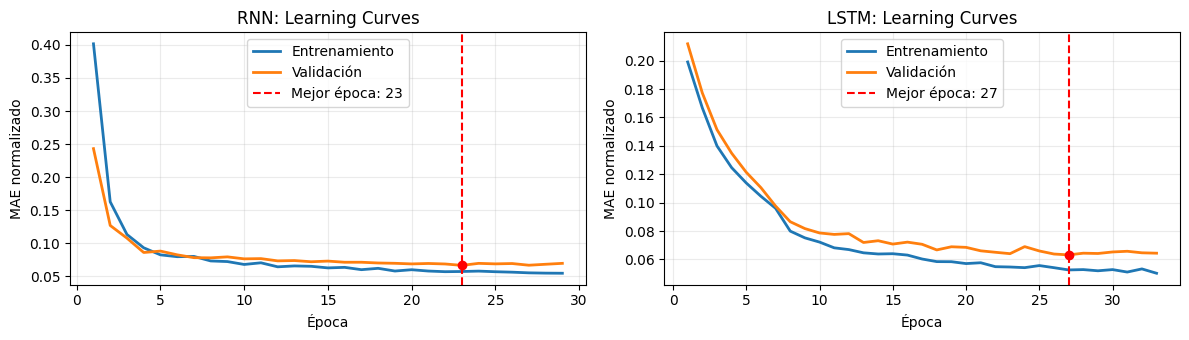

In [39]:
# Entrenar, guardar y visualizar las curvas de aprendizaje de RNN y LSTM
historiales = {}

for r in mejores.itertuples(index=False):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    modelo = crear_red(r.Modelo, int(r.Capas), int(r.Neuronas))  # Arquitectura seleccionada
    stop = EarlyStopping(monitor='val_loss', mode='min', patience=6,
                         restore_best_weights=True)  # Parada anticipada
    hist = modelo.fit(Xtr, ytr, validation_data=(Xva, yva),
                      epochs=35, batch_size=BATCH, callbacks=[stop],
                      verbose=0, shuffle=False)  # Entrenamiento final
    historiales[r.Modelo] = hist.history  # Guarda loss y val_loss
    print(f"{r.Modelo}: {len(hist.history['loss'])} épocas registradas")

# Graficar las curvas de aprendizaje
fig, ax = plt.subplots(1, len(historiales), figsize=(12, 3.5))
ax = np.atleast_1d(ax)

for a, (nombre, h) in zip(ax, historiales.items()):
    epocas = np.arange(1, len(h['loss']) + 1)
    mejor = np.argmin(h['val_loss']) + 1  # Mejor época de validación

    a.plot(epocas, h['loss'], label='Entrenamiento', lw=2)
    a.plot(epocas, h['val_loss'], label='Validación', lw=2)
    a.axvline(mejor, color='red', ls='--', label=f'Mejor época: {mejor}')
    a.scatter(mejor, h['val_loss'][mejor - 1], color='red', zorder=5)
    a.set(title=f'{nombre}: Learning Curves',
          xlabel='Época', ylabel='MAE normalizado')
    a.legend()
    a.grid(alpha=0.25)

plt.tight_layout()
plt.show()


RNN: 29 épocas | MAE = 256.395
LSTM: 33 épocas | MAE = 241.474


,Modelo,MAE,RMSE,R2,Bias,Épocas
0,LSTM,241.474,417.219,0.866,-27.554,33
1,RNN,256.395,433.345,0.856,-46.949,29
2,Naive 24 h,333.755,639.304,0.686,0.085,0


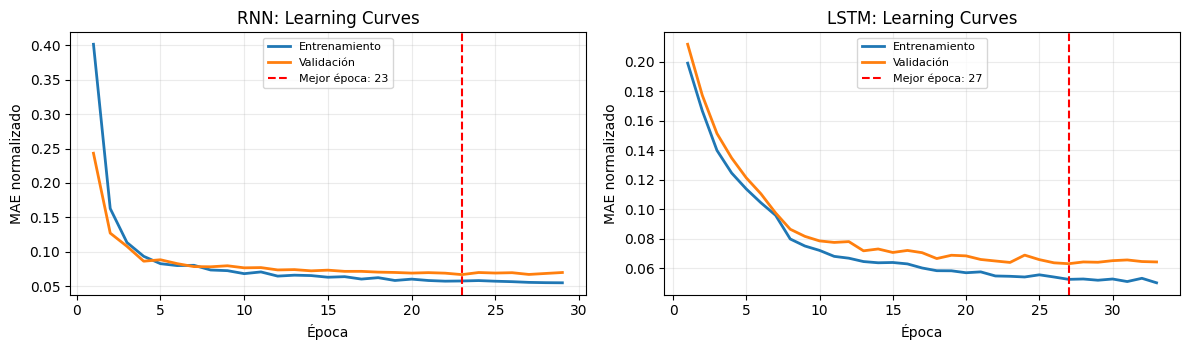

In [44]:
# Entrenamiento final: RNN y LSTM, historiales y predicciones sobre TEST
historiales, predicciones, modelos_finales, resultados_test = {}, {}, {}, []
observado = sc.inverse_transform(ytest.reshape(-1, 1)).ravel()  # Radiación real/imputada de TEST

for r in mejores.itertuples(index=False):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    modelo = crear_red(r.Modelo, int(r.Capas), int(r.Neuronas))  # Mejor arquitectura de cada familia
    stop = EarlyStopping(monitor='val_loss', mode='min', patience=6,
                         restore_best_weights=True)  # Recupera los mejores pesos

    hist = modelo.fit(Xtr, ytr, validation_data=(Xva, yva),
                      epochs=35, batch_size=BATCH, callbacks=[stop],
                      verbose=0, shuffle=False)  # Entrenamiento cronológico

    p = sc.inverse_transform(modelo.predict(Xtest, verbose=0)).ravel()  # Predicción en unidades originales
    historiales[r.Modelo] = hist.history  # Pérdidas por época
    predicciones[r.Modelo] = p  # Predicciones del mismo modelo entrenado
    modelos_finales[r.Modelo] = modelo  # Conserva el modelo

    resultados_test.append({
        'Modelo': r.Modelo, 'MAE': mean_absolute_error(observado, p),
        'RMSE': np.sqrt(mean_squared_error(observado, p)),
        'R2': r2_score(observado, p), 'Bias': np.mean(p - observado),
        'Épocas': len(hist.history['loss'])
    })
    print(f"{r.Modelo}: {len(hist.history['loss'])} épocas | MAE = {mean_absolute_error(observado, p):.3f}")

# Referencia estacional de 24 horas
if WINDOW == 24:
    naive = sc.inverse_transform(np.asarray(xtest[:-24]).reshape(-1, 1)).ravel()
    if len(naive) == len(observado):
        predicciones['Naive 24 h'] = naive
        resultados_test.append({
            'Modelo': 'Naive 24 h', 'MAE': mean_absolute_error(observado, naive),
            'RMSE': np.sqrt(mean_squared_error(observado, naive)),
            'R2': r2_score(observado, naive), 'Bias': np.mean(naive - observado),
            'Épocas': 0
        })

res_test = pd.DataFrame(resultados_test).sort_values('MAE').reset_index(drop=True)
display(res_test.round(3))  # Métricas correspondientes a estos entrenamientos

# Curvas de aprendizaje (Learning Curves)
fig, ax = plt.subplots(1, len(historiales), figsize=(12, 3.6))
ax = np.atleast_1d(ax)

for a, (nombre, h) in zip(ax, historiales.items()):
    epocas = np.arange(1, len(h['loss']) + 1)
    mejor = np.argmin(h['val_loss']) + 1
    a.plot(epocas, h['loss'], lw=2, label='Entrenamiento')
    a.plot(epocas, h['val_loss'], lw=2, label='Validación')
    a.axvline(mejor, color='red', ls='--', label=f'Mejor época: {mejor}')
    a.set(title=f'{nombre}: Learning Curves', xlabel='Época', ylabel='MAE normalizado')
    a.legend(fontsize=8)
    a.grid(alpha=0.25)

plt.tight_layout()
plt.show()


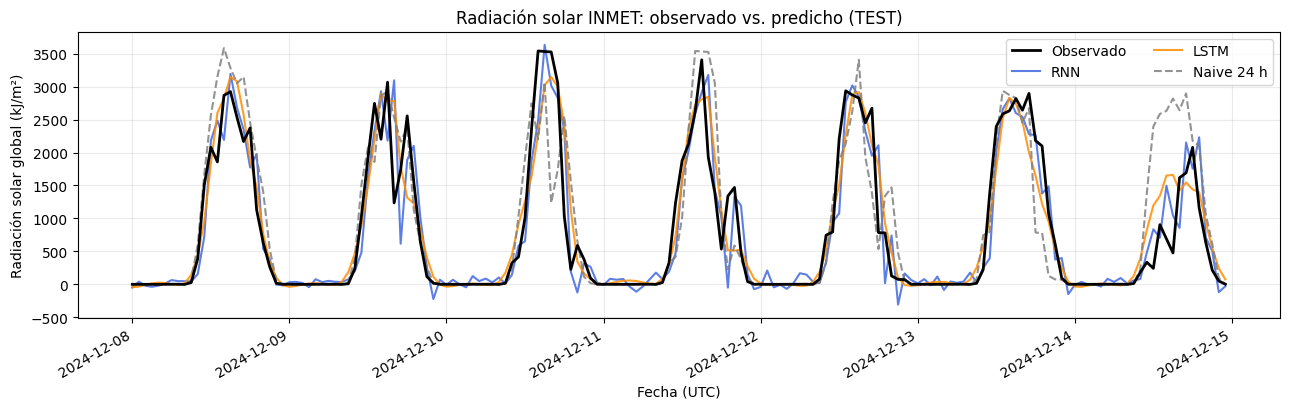

In [45]:

# Pronósticos de los modelos entrenados: primeras 168 horas (7 días)
fechas_prueba = serie_test.index
if len(fechas_prueba) != len(observado):
    raise ValueError("Las fechas no coinciden con las observaciones de TEST.")

n_plot = min(168, len(observado))
colores = {'RNN': 'royalblue', 'LSTM': 'darkorange', 'Naive 24 h': 'gray'}

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(fechas_prueba[:n_plot], observado[:n_plot],
        color='black', lw=2, label='Observado', zorder=5)

for nombre, p in predicciones.items():
    ax.plot(fechas_prueba[:n_plot], p[:n_plot],
            color=colores.get(nombre), lw=1.5, alpha=0.85,
            ls='--' if 'Naive' in nombre else '-', label=nombre)

ax.set(title='Radiación solar INMET: observado vs. predicho (TEST)',
       xlabel='Fecha (UTC)', ylabel='Radiación solar global (kJ/m²)')
ax.legend(ncol=2)
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


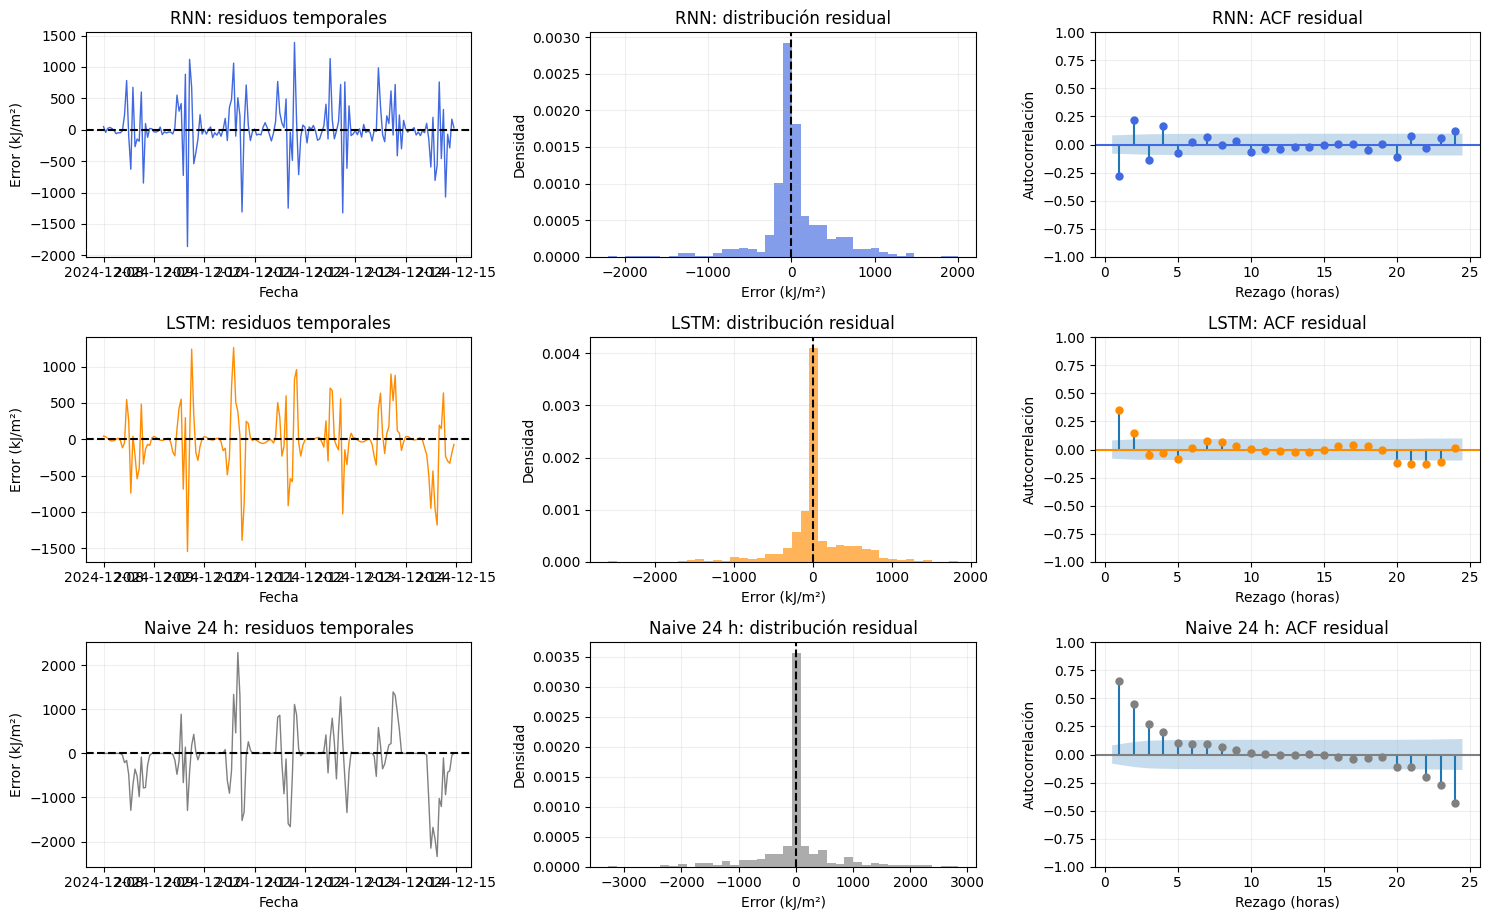

In [47]:

# Diagnóstico residual: comportamiento temporal, distribución y autocorrelación
from statsmodels.graphics.tsaplots import plot_acf

residuales = {nombre: observado - np.asarray(p).ravel()
              for nombre, p in predicciones.items()}  # Residuo por modelo

fig, ax = plt.subplots(len(residuales), 3,
                       figsize=(15, 3.1 * len(residuales)), squeeze=False)

for i, (nombre, e) in enumerate(residuales.items()):
    color = colores.get(nombre, 'green')

    ax[i, 0].plot(fechas_prueba[:n_plot], e[:n_plot], color=color, lw=1)
    ax[i, 0].axhline(0, color='black', ls='--')
    ax[i, 0].set(title=f'{nombre}: residuos temporales',
                 xlabel='Fecha', ylabel='Error (kJ/m²)')

    ax[i, 1].hist(e, bins=40, density=True, color=color, alpha=0.65)
    ax[i, 1].axvline(0, color='black', ls='--')
    ax[i, 1].set(title=f'{nombre}: distribución residual',
                 xlabel='Error (kJ/m²)', ylabel='Densidad')

    plot_acf(e, lags=24, zero=False, ax=ax[i, 2], color=color)
    ax[i, 2].set(title=f'{nombre}: ACF residual', xlabel='Rezago (horas)',
                 ylabel='Autocorrelación')

    for a in ax[i]:
        a.grid(alpha=0.20)

plt.tight_layout()
plt.show()


In [52]:

# TEST: predicciones, métricas y pruebas de independencia residual
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import bds

alpha = 0.05  # Nivel de significancia del 5 %

if not predicciones:
    print("No hay predicciones. Ejecuta primero la evaluación final.")
else:
    observado = sc.inverse_transform(ytest.reshape(-1, 1)).ravel()
    fechas = serie_test.index
    if len(fechas) != len(observado):
        raise ValueError("Las fechas y los valores de TEST no coinciden.")

    tabla_test = pd.DataFrame({'Observado': observado}, index=fechas)
    pruebas = []

    for nombre, p in predicciones.items():
        p = np.asarray(p).ravel()
        if len(p) != len(observado):
            raise ValueError(f"Dimensiones incorrectas: {nombre}")

        e = observado - p  # Residuos: observado - predicho
        if not np.isfinite(e).all():
            raise ValueError(f"Existen residuos no finitos en {nombre}")

        tabla_test[f'Pred_{nombre}'] = p
        tabla_test[f'Error_{nombre}'] = e

        # Ljung-Box: autocorrelación residual hasta 24 horas
        lb = acorr_ljungbox(e, lags=[1, 6, 12, 24], return_df=True)
        p_lb = float(lb.loc[24, 'lb_pvalue'])

        # BDS: contraste i.i.d. sobre los últimos 400 residuos consecutivos
        try:
            _, p_bds = bds(e[-min(400, len(e)):], max_dim=2)
            p_bds = float(np.asarray(p_bds).ravel()[0])
        except (ValueError, FloatingPointError, MemoryError) as exc:
            print(f"BDS no disponible para {nombre}: {exc}")
            p_bds = np.nan

        # Diagnóstico al nivel de significancia establecido
        if p_lb < alpha:
            diagnostico = 'No: autocorrelación (LB)'
        elif np.isfinite(p_bds) and p_bds < alpha:
            diagnostico = 'No i.i.d. (BDS)'
        elif np.isfinite(p_bds):
            diagnostico = 'No se rechaza H0'
        else:
            diagnostico = 'Inconcluso'

        pruebas.append({
            'Modelo': nombre,
            'LB_p(1)': lb.loc[1, 'lb_pvalue'],
            'LB_p(6)': lb.loc[6, 'lb_pvalue'],
            'LB_p(12)': lb.loc[12, 'lb_pvalue'],
            'LB_p(24)': p_lb,
            'BDS_p': p_bds,
            'Independencia': diagnostico
        })

    # Tabla 1: valores observados, predicciones y errores
    tabla_test.index.name = 'Fecha_UTC'
    print(f"Total de observaciones TEST: {len(tabla_test)}")
    display(tabla_test.head(24).round(3))

    # Tabla 2: métricas y pruebas residuales por modelo
    tabla_pruebas = pd.DataFrame(pruebas)
    resumen_final = res_test.copy()
    resumen_final['Modelo'] = resumen_final['Modelo'].replace(
        {'Naive estacional (24 h)': 'Naive 24 h'})
    resumen_final = resumen_final.merge(tabla_pruebas, on='Modelo', how='left')

    print("\nEvaluación final y diagnóstico de independencia:")
    display(resumen_final.round(4))

    # Exportar resultados completos
    tabla_test.to_csv('predicciones_test_INMET.csv', encoding='utf-8-sig')
    resumen_final.to_csv('metricas_pruebas_INMET.csv', index=False)



Total de observaciones TEST: 576


,Observado,Pred_RNN,Error_RNN,Pred_LSTM,Error_LSTM,Pred_Naive 24 h,Error_Naive 24 h
Fecha_UTC,,,,,,,
2024-12-08 00:00:00,1.760000,-47.693001,49.452999,-40.875000,42.634998,1.760,-0.0
2024-12-08 01:00:00,1.080000,41.959999,-40.880001,-33.564999,34.645000,1.080,-0.0
2024-12-08 02:00:00,1.083000,-22.034000,23.117001,-7.598000,8.681000,1.083,0.0
2024-12-08 03:00:00,1.300000,-36.150002,37.450001,15.788000,-14.488000,1.300,-0.0
2024-12-08 04:00:00,0.750000,-19.077000,19.827000,26.691999,-25.941999,0.750,0.0
2024-12-08 05:00:00,2.133000,12.571000,-10.437000,21.562000,-19.429001,2.133,-0.0
2024-12-08 06:00:00,2.733000,65.680000,-62.946999,4.287000,-1.554000,2.733,0.0
2024-12-08 07:00:00,3.067000,50.161999,-47.095001,-9.822000,12.889000,3.067,0.0
2024-12-08 08:00:00,0.250000,49.159000,-48.909000,16.804001,-16.554001,0.250,0.0



Evaluación final y diagnóstico de independencia:


,Modelo,MAE,RMSE,R2,Bias,Épocas,LB_p(1),LB_p(6),LB_p(12),LB_p(24),BDS_p,Independencia
0,LSTM,241.4737,417.2186,0.8664,-27.5545,33,0.0,0.0,0.0,0.0,0.0,No: autocorrelación (LB)
1,RNN,256.3947,433.3452,0.8559,-46.9489,29,0.0,0.0,0.0,0.0,0.0,No: autocorrelación (LB)
2,Naive 24 h,333.7547,639.3036,0.6864,0.0852,0,0.0,0.0,0.0,0.0,0.0,No: autocorrelación (LB)
